In [11]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import time
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Dropout,
    GlobalAveragePooling2D,
    Dense
)
from tensorflow.keras.utils import plot_model
from tensorflow.keras.optimizers import Adam

In [1]:


from pathlib import Path

dataset_path = Path("../data")

classes = []

for folder in dataset_path.iterdir():
    if folder.is_dir():
        classes.append(folder.name)

print("Les classes :", classes)

Les classes : ['glioma', 'meningioma', 'notumor', 'pituitary']


3. Charger les images et vérifier les extensions

In [4]:
images = []
labels = []

extensions_valides = {".jpeg", ".jpg", ".bmp", ".png"}

for classe in classes:
    dossier_classe = dataset_path / classe

    for fichier in dossier_classe.iterdir():

        if not fichier.is_file():
            continue

        if fichier.suffix.lower() not in extensions_valides:
            continue

        try:
            image = cv2.imread(str(fichier))

            if image is None:
                print("Image illisible :", fichier)
                continue

            image = cv2.resize(image, (224, 224))
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

            images.append(image)
            labels.append(classe)

        except Exception as erreur:
            print("Erreur :", fichier, erreur)

print("Nombre d'images chargées :", len(images))
print("Nombre de labels :", len(labels))
X = np.array(images)
y = np.array(labels)

print("Shape de X :", X.shape)
print("Shape de y :", y.shape)

Nombre d'images chargées : 7023
Nombre de labels : 7023
Shape de X : (7023, 224, 224, 3)
Shape de y : (7023,)


diagramme de image


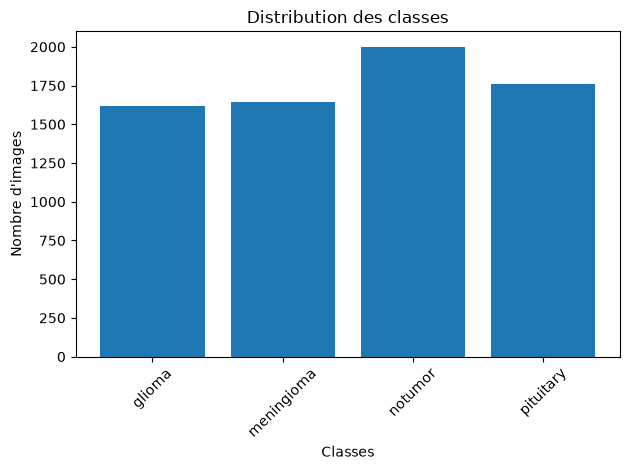

In [5]:
classes_uniques, nombres = np.unique(y, return_counts=True)

plt.bar(classes_uniques, nombres)
plt.xlabel("Classes")
plt.ylabel("Nombre d'images")
plt.title("Distribution des classes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

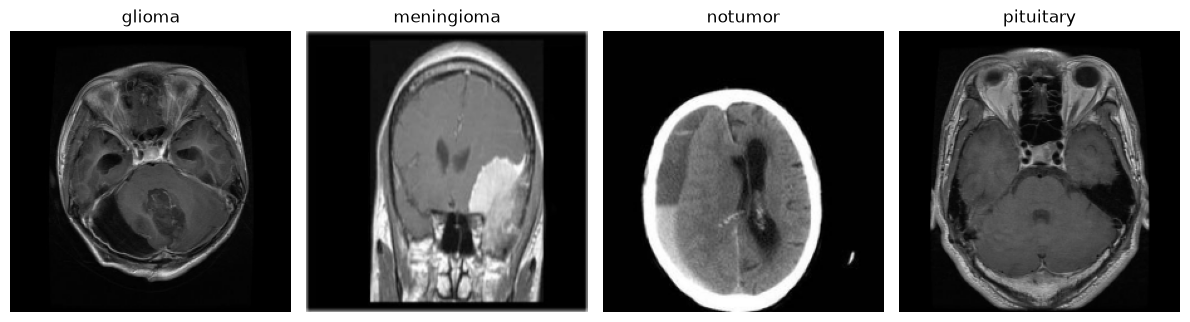

In [6]:
plt.figure(figsize=(12, 8))

for i, classe in enumerate(classes_uniques):
    indices = np.where(y == classe)[0]

    if len(indices) == 0:
        continue

    index = indices[0]

    plt.subplot(1, len(classes_uniques), i + 1)
    plt.imshow(X[index])
    plt.title(classe)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [10]:
encoder = LabelEncoder()

y_encoded = encoder.fit_transform(y)

print("Classes :", encoder.classes_)
print("Labels numériques :", y_encoded[:10])
print("Shape categorical :", y_encoded.shape)
for classe, numero in zip(encoder.classes_, range(len(encoder.classes_))):
    print(classe, "=", numero)

Classes : ['glioma' 'meningioma' 'notumor' 'pituitary']
Labels numériques : [0 0 0 0 0 0 0 0 0 0]
Shape categorical : (7023,)
glioma = 0
meningioma = 1
notumor = 2
pituitary = 3


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("X_train :", X_train.shape)
print("X_test :", X_test.shape)

X_train : (5618, 224, 224, 3)
X_test : (1405, 224, 224, 3)


In [ ]:
model = Sequential([
    tf.keras.Input(shape=(224, 224, 3)),

    Conv2D(32, (3, 3), activation="relu", padding="same"),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(64, (3, 3), activation="relu", padding="same"),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(128, (3, 3), activation="relu", padding="same"),
    MaxPooling2D(pool_size=(2, 2)),

    GlobalAveragePooling2D(),

    Dense(128, activation="relu"),
    Dropout(0.5),

    Dense(4, activation="softmax")
])


E0000 00:00:1792343157.383596  122129 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



In [13]:
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,276 (430.77 KB)

 Trainable params: 110,276 (430.77 KB)

 Non-trainable params: 0 (0.00 B)

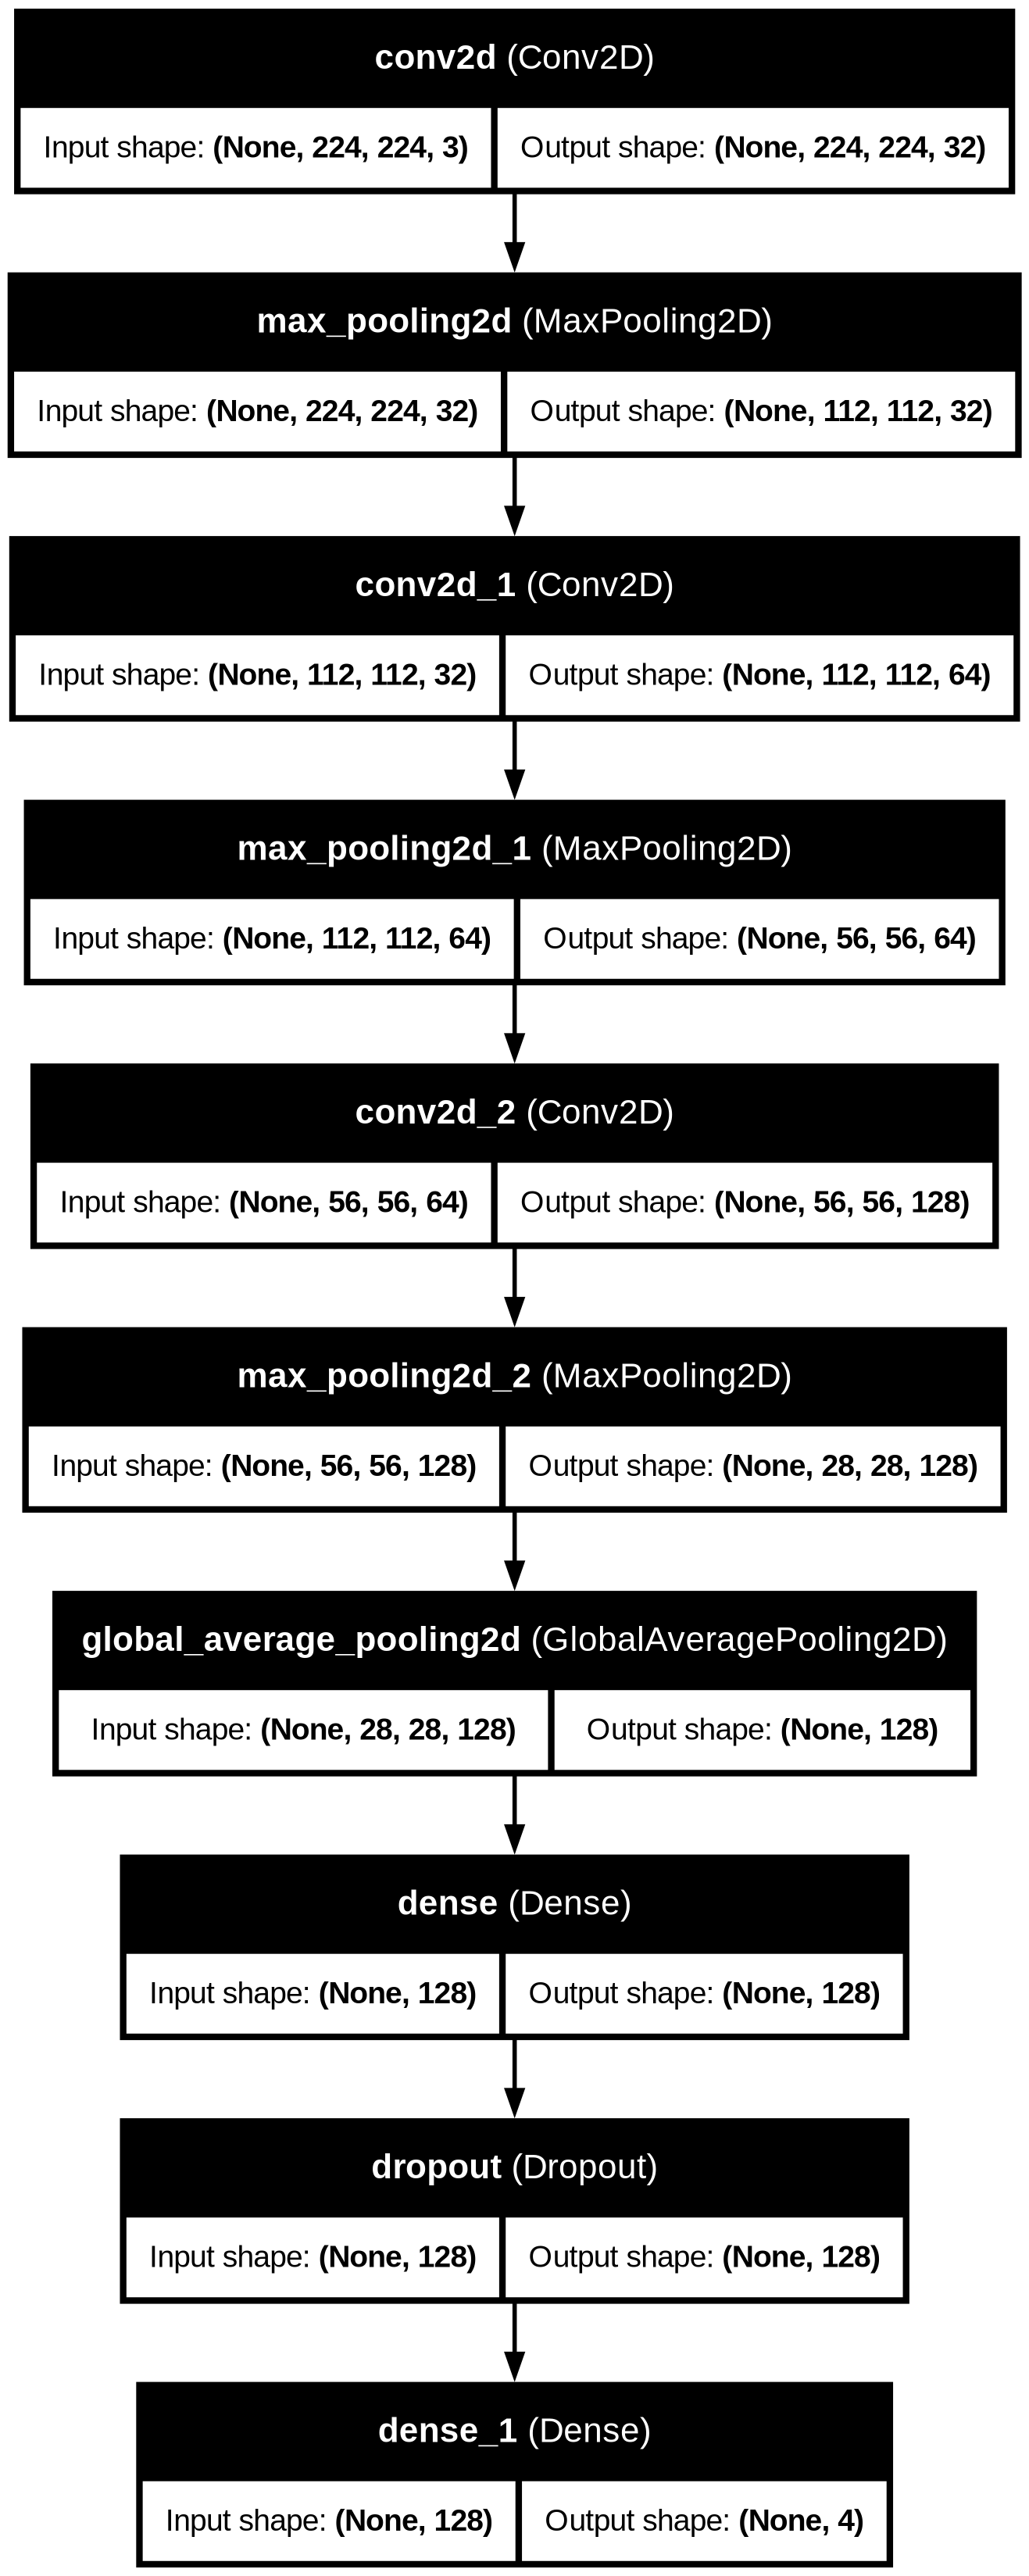

In [14]:
plot_model(
    model,
    to_file="architecture_cnn.png",
    show_shapes=True,
    show_layer_names=True
)

In [15]:
epochs = 15
batch_size = 32

debut = time.time()

history = model.fit(
    X_train,
    y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_split=0.2
)

fin = time.time()

duree = fin - debut

print(f"Durée d'entraînement : {duree:.2f} secondes")

Epoch 1/15
141/141 ━━━━━━━━━━━━━━━━━━━━ 91s 633ms/step - accuracy: 0.3852 - loss: 1.2299 - val_accuracy: 0.6343 - val_loss: 1.0177
Epoch 2/15
141/141 ━━━━━━━━━━━━━━━━━━━━ 83s 589ms/step - accuracy: 0.5839 - loss: 0.9952 - val_accuracy: 0.6628 - val_loss: 0.8924
Epoch 3/15
141/141 ━━━━━━━━━━━━━━━━━━━━ 86s 613ms/step - accuracy: 0.6389 - loss: 0.8981 - val_accuracy: 0.7002 - val_loss: 0.7828
Epoch 4/15
141/141 ━━━━━━━━━━━━━━━━━━━━ 87s 614ms/step - accuracy: 0.6900 - loss: 0.8009 - val_accuracy: 0.7135 - val_loss: 0.7117
Epoch 5/15
141/141 ━━━━━━━━━━━━━━━━━━━━ 88s 625ms/step - accuracy: 0.7214 - loss: 0.7180 - val_accuracy: 0.7331 - val_loss: 0.6598
Epoch 6/15
141/141 ━━━━━━━━━━━━━━━━━━━━ 89s 631ms/step - accuracy: 0.7350 - loss: 0.6739 - val_accuracy: 0.7447 - val_loss: 0.6489
Epoch 7/15
141/141 ━━━━━━━━━━━━━━━━━━━━ 87s 613ms/step - accuracy: 0.7477 - loss: 0.6474 - val_accuracy: 0.7429 - val_loss: 0.6410
Epoch 8/15
141/141 ━━━━━━━━━━━━━━━━━━━━ 85s 606ms/step - accuracy: 0.7581 - loss: 0

In [16]:
from pathlib import Path
import time
from tensorflow.keras.callbacks import ModelCheckpoint

# Créer le dossier models s'il n'existe pas
dossier_models = Path("models")
dossier_models.mkdir(parents=True, exist_ok=True)

# Sauvegarder le meilleur modèle
checkpoint = ModelCheckpoint(
    filepath=str(dossier_models / "meilleur_cnn.keras"),
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

# Entraînement
debut = time.time()

history = model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=32,
    validation_split=0.2,
    callbacks=[checkpoint]
)

fin = time.time()
print(f"Durée d'entraînement : {(fin - debut) / 60:.2f} minutes")

Epoch 1/15
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 534ms/step - accuracy: 0.8044 - loss: 0.4966
Epoch 1: val_accuracy improved from None to 0.80160, saving model to models/meilleur_cnn.keras

Epoch 1: finished saving model to models/meilleur_cnn.keras
141/141 ━━━━━━━━━━━━━━━━━━━━ 87s 612ms/step - accuracy: 0.8044 - loss: 0.4966 - val_accuracy: 0.8016 - val_loss: 0.5147
Epoch 2/15
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 568ms/step - accuracy: 0.8117 - loss: 0.4918
Epoch 2: val_accuracy improved from 0.80160 to 0.81673, saving model to models/meilleur_cnn.keras

Epoch 2: finished saving model to models/meilleur_cnn.keras
141/141 ━━━━━━━━━━━━━━━━━━━━ 86s 612ms/step - accuracy: 0.8117 - loss: 0.4918 - val_accuracy: 0.8167 - val_loss: 0.4708
Epoch 3/15
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 541ms/step - accuracy: 0.8062 - loss: 0.4862
Epoch 3: val_accuracy improved from 0.81673 to 0.82206, saving model to models/meilleur_cnn.keras

Epoch 3: finished saving model to models/meilleur_cnn.keras
141/141 ━━━━━━━━━━━━━━

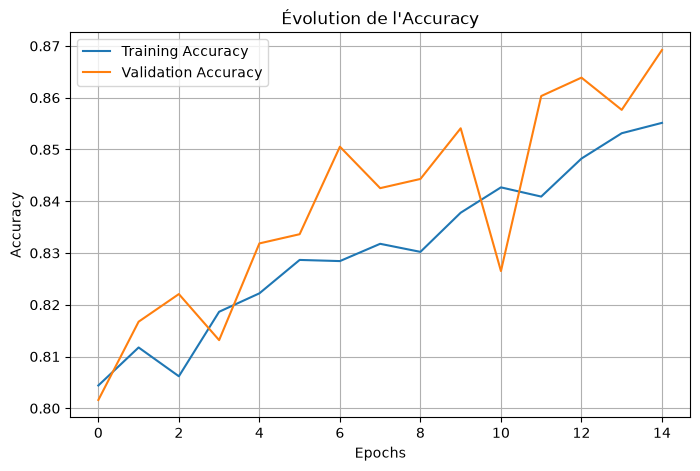

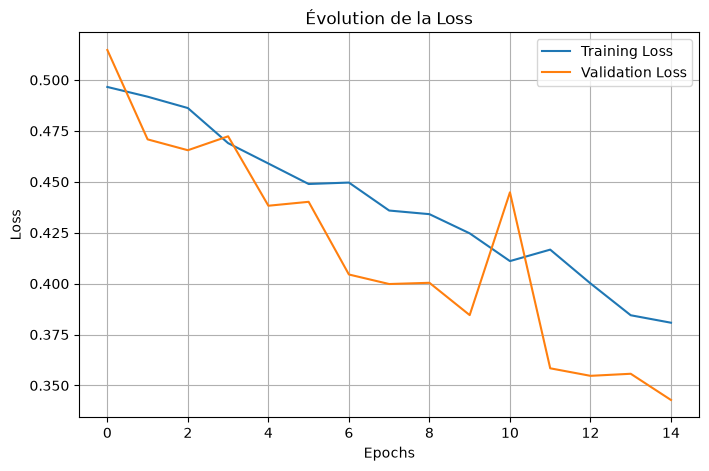

In [17]:
import matplotlib.pyplot as plt

# Courbe Accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Évolution de l'Accuracy")
plt.legend()
plt.grid()
plt.show()

# Courbe Loss
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Évolution de la Loss")
plt.legend()
plt.grid()
plt.show()

44/44 ━━━━━━━━━━━━━━━━━━━━ 9s 189ms/step


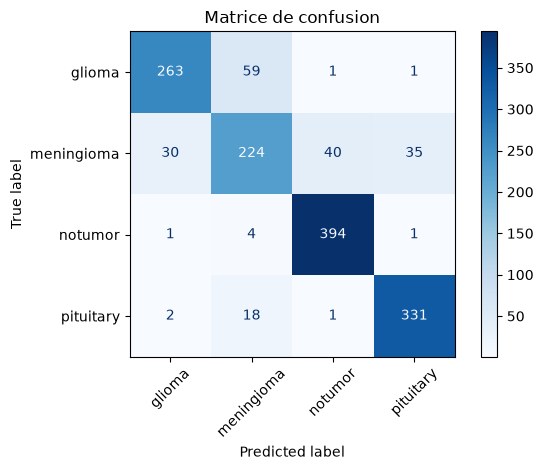

              precision    recall  f1-score   support

      glioma       0.89      0.81      0.85       324
  meningioma       0.73      0.68      0.71       329
     notumor       0.90      0.98      0.94       400
   pituitary       0.90      0.94      0.92       352

    accuracy                           0.86      1405
   macro avg       0.86      0.85      0.85      1405
weighted avg       0.86      0.86      0.86      1405



In [18]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# Noms des classes dans l'ordre du LabelEncoder
classes = ["glioma", "meningioma", "notumor", "pituitary"]

# Prédictions
y_prob = model.predict(X_test)
y_pred = np.argmax(y_prob, axis=1)

# Matrice de confusion
cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2, 3])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Matrice de confusion")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Rapport de classification
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1, 2, 3],
    target_names=classes,
    zero_division=0
))

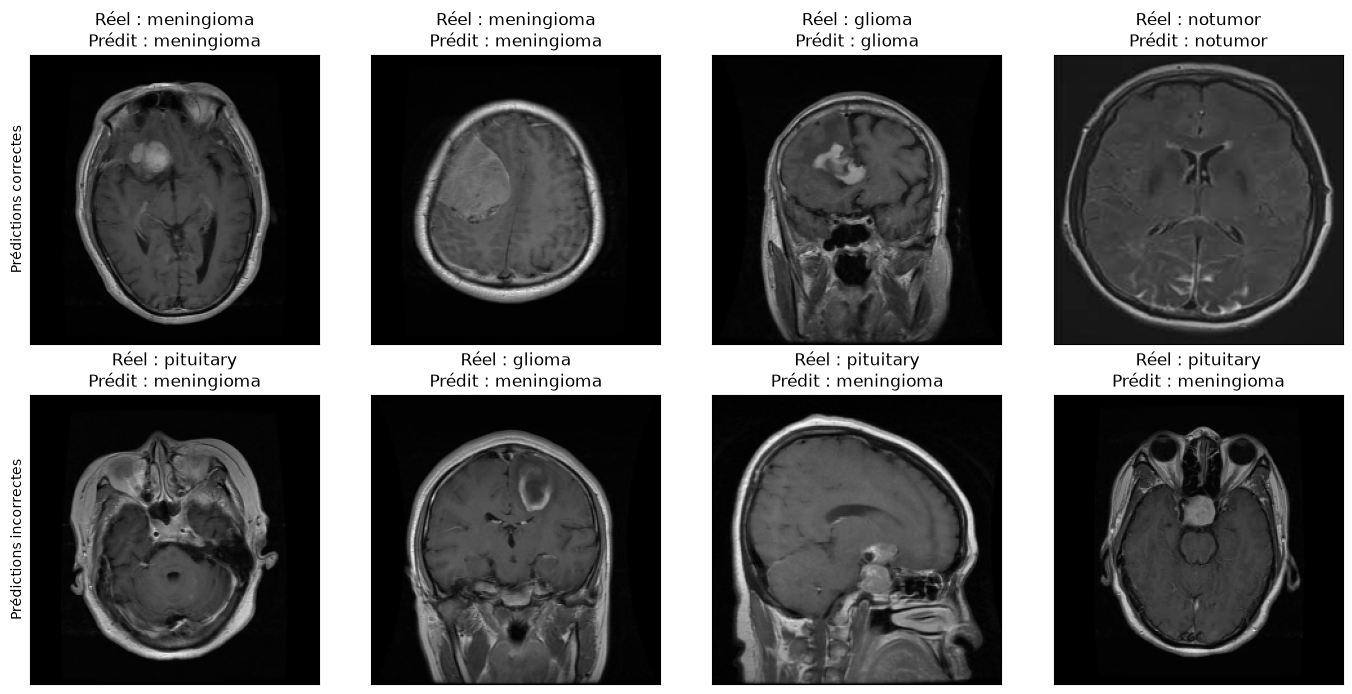

In [19]:
import numpy as np
import matplotlib.pyplot as plt

# Indices des prédictions correctes et incorrectes
indices_corrects = np.where(y_pred == y_test)[0]
indices_incorrects = np.where(y_pred != y_test)[0]

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

groupes = [
    (indices_corrects, "Prédictions correctes"),
    (indices_incorrects, "Prédictions incorrectes")
]

for ligne, (indices, titre) in enumerate(groupes):
    for colonne in range(4):
        ax = axes[ligne, colonne]

        if colonne < len(indices):
            i = indices[colonne]

            ax.imshow(X_test[i])
            ax.set_title(
                f"Réel : {classes[y_test[i]]}\n"
                f"Prédit : {classes[y_pred[i]]}"
            )
        else:
            ax.axis("off")

        ax.set_xticks([])
        ax.set_yticks([])

    axes[ligne, 0].set_ylabel(titre)

plt.tight_layout()
plt.show()

In [20]:
from pathlib import Path

dossier_models = Path("models")
dossier_models.mkdir(parents=True, exist_ok=True)

model.save(dossier_models / "brainscan_cnn.keras")

In [29]:

import cv2
import numpy as np
from tensorflow.keras.models import load_model

model = load_model("models/brainscan_cnn.keras")

classes = ["glioma", "meningioma", "notumor", "pituitary"]


def predict_image(path):
    # 1. Lire l'image
    image = cv2.imread(str(path))

    if image is None:
        raise ValueError("Impossible de lire l'image.")

    # 2. Prétraiter l'image comme pendant l'entraînement
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, (224, 224))
    image = image.astype("float32") / 255.0
    image = np.expand_dims(image, axis=0)

    # 3. Obtenir les probabilités des 4 classes
    probabilities = model.predict(image, verbose=0)[0]

    # 4. Afficher les probabilités
    for classe, proba in zip(classes, probabilities):
        print(f"{classe}: {proba * 100:.2f}%")

    # 5. Trouver la classe ayant la probabilité la plus élevée
    # 5. Trouver la classe ayant la probabilité la plus élevée
    index = np.argmax(probabilities)

    predicted_class = classes[index]
    confidence = probabilities[index]

    return predicted_class, confidence


In [31]:
classe, confiance = predict_image(
    "../data/image.png"
)

print("Classe prédite :", classe)
print(f"Confiance : {confiance * 100:.2f}%")

glioma: 0.27%
meningioma: 2.27%
notumor: 1.73%
pituitary: 95.73%
Classe prédite : pituitary
Confiance : 95.73%
